<a href="https://colab.research.google.com/github/Shreyas408315/Gen-AI/blob/main/Mini_GPT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Mini GPT from Scratch
# Step 1: Environment Setup

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", device)


PyTorch version: 2.11.0+cu130
GPU available: True
Using device: cuda


In [2]:

import urllib.request

# Download Tiny Shakespeare dataset
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"

filename = "input.txt"

urllib.request.urlretrieve(url, filename)

# Read dataset
with open(filename, "r", encoding="utf-8") as f:
    text = f.read()

# Display dataset information
print("Dataset downloaded successfully!")
print("Total characters:", len(text))

print("\nSample text:\n")
print(text[:500])


Dataset downloaded successfully!
Total characters: 1115394

Sample text:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


In [3]:

# Step 3: Character-Level Tokenizer

# Get all unique characters from dataset
chars = sorted(list(set(text)))

# Vocabulary size
vocab_size = len(chars)

print("Unique characters:", chars)
print("Vocabulary size:", vocab_size)

# Create character-to-integer mapping
stoi = {ch: i for i, ch in enumerate(chars)}

# Create integer-to-character mapping
itos = {i: ch for i, ch in enumerate(chars)}

# Encoder: text to numbers
def encode(s):
    return [stoi[c] for c in s]

# Decoder: numbers to text
def decode(ids):
    return ''.join([itos[i] for i in ids])

print("\nTokenizer created successfully!")

# Test tokenizer
sample = "Hello Shakespeare"

encoded = encode(sample)
decoded = decode(encoded)

print("\nOriginal text:", sample)
print("Token IDs:", encoded)
print("Decoded text:", decoded)


Unique characters: ['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
Vocabulary size: 65

Tokenizer created successfully!

Original text: Hello Shakespeare
Token IDs: [20, 43, 50, 50, 53, 1, 31, 46, 39, 49, 43, 57, 54, 43, 39, 56, 43]
Decoded text: Hello Shakespeare


In [4]:

data = torch.tensor(encode(text), dtype=torch.long)

print("Data shape:", data.shape)
print("First 100 token IDs:")
print(data[:100])


Data shape: torch.Size([1115394])
First 100 token IDs:
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59])


In [5]:

# 90% training, 10% validation
split_index = int(0.9 * len(data))

train_data = data[:split_index]
val_data = data[split_index:]

print("Training data:", len(train_data))
print("Validation data:", len(val_data))


Training data: 1003854
Validation data: 111540


In [6]:

# Hyperparameters
batch_size = 64
block_size = 128

def get_batch(split):

    data_split = train_data if split == "train" else val_data

    ix = torch.randint(
        len(data_split) - block_size - 1,
        (batch_size,)
    )

    x = torch.stack([
        data_split[i:i + block_size] for i in ix
    ])

    y = torch.stack([
        data_split[i + 1:i + block_size + 1] for i in ix
    ])

    x = x.to(device)
    y = y.to(device)

    return x, y


xb, yb = get_batch("train")

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)


Input shape: torch.Size([64, 128])
Target shape: torch.Size([64, 128])


In [7]:

# GPT architecture settings

n_embd = 128       # Embedding dimension
n_head = 4         # Attention heads
n_layer = 4        # Transformer blocks
dropout = 0.1      # Dropout probability

assert n_embd % n_head == 0

print("Embedding dimension:", n_embd)
print("Attention heads:", n_head)
print("Transformer blocks:", n_layer)
print("Vocabulary size:", vocab_size)


Embedding dimension: 128
Attention heads: 4
Transformer blocks: 4
Vocabulary size: 65


In [8]:

class EmbeddingLayer(nn.Module):

    def __init__(self, vocab_size, n_embd, block_size):

        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding = nn.Embedding(
            block_size, n_embd
        )

    def forward(self, idx):

        B, T = idx.shape

        tok_emb = self.token_embedding(idx)

        pos = torch.arange(T, device=idx.device)

        pos_emb = self.position_embedding(pos)

        x = tok_emb + pos_emb

        return x


embedding_layer = EmbeddingLayer(
    vocab_size, n_embd, block_size
).to(device)

print("Embedding layer created!")


Embedding layer created!


In [9]:

class Head(nn.Module):

    def __init__(self, head_size):

        super().__init__()

        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size))
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)

        # Attention scores
        wei = q @ k.transpose(-2, -1)

        wei = wei * (k.shape[-1] ** -0.5)

        # Causal masking
        wei = wei.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        # Softmax
        wei = F.softmax(wei, dim=-1)

        wei = self.dropout(wei)

        v = self.value(x)

        out = wei @ v

        return out


print("Self-attention head created!")


Self-attention head created!


In [10]:

class MultiHeadAttention(nn.Module):

    def __init__(self, num_heads, head_size):

        super().__init__()

        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])

        self.proj = nn.Linear(
            num_heads * head_size,
            n_embd
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        out = torch.cat(
            [h(x) for h in self.heads],
            dim=-1
        )

        out = self.proj(out)

        out = self.dropout(out)

        return out


print("Multi-head attention created!")


Multi-head attention created!


In [11]:

class FeedForward(nn.Module):

    def __init__(self, n_embd):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(n_embd, 4 * n_embd),

            nn.ReLU(),

            nn.Linear(4 * n_embd, n_embd),

            nn.Dropout(dropout)

        )

    def forward(self, x):

        return self.net(x)


print("Feed-forward network created!")


Feed-forward network created!


In [12]:

class Block(nn.Module):

    def __init__(self, n_embd, n_head):

        super().__init__()

        head_size = n_embd // n_head

        self.sa = MultiHeadAttention(
            n_head, head_size
        )

        self.ffwd = FeedForward(n_embd)

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):

        # Attention + residual connection
        x = x + self.sa(self.ln1(x))

        # Feed-forward + residual connection
        x = x + self.ffwd(self.ln2(x))

        return x


print("Transformer block created!")


Transformer block created!


In [13]:

class GPTLanguageModel(nn.Module):

    def __init__(self):

        super().__init__()

        # Token and positional embeddings
        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding_table = nn.Embedding(
            block_size, n_embd
        )

        # Transformer blocks
        self.blocks = nn.Sequential(*[
            Block(n_embd, n_head)
            for _ in range(n_layer)
        ])

        # Final normalization
        self.ln_f = nn.LayerNorm(n_embd)

        # Output layer
        self.lm_head = nn.Linear(n_embd, vocab_size)

        # Initialize weights
        self.apply(self._init_weights)

    def _init_weights(self, module):

        if isinstance(module, nn.Linear):

            torch.nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):

            torch.nn.init.normal_(
                module.weight,
                mean=0.0,
                std=0.02
            )

    def forward(self, idx, targets=None):

        B, T = idx.shape

        if T > block_size:
            raise ValueError("Sequence exceeds block_size")

        # Token embeddings
        tok_emb = self.token_embedding_table(idx)

        # Positional embeddings
        pos = torch.arange(T, device=idx.device)

        pos_emb = self.position_embedding_table(pos)

        # Combine embeddings
        x = tok_emb + pos_emb

        # Transformer blocks
        x = self.blocks(x)

        # Final layer normalization
        x = self.ln_f(x)

        # Logits
        logits = self.lm_head(x)

        loss = None

        if targets is not None:

            B, T, C = logits.shape

            loss = F.cross_entropy(
                logits.reshape(B * T, C),
                targets.reshape(B * T)
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):

        for _ in range(max_new_tokens):

            # Crop context
            idx_cond = idx[:, -block_size:]

            # Forward pass
            logits, loss = self(idx_cond)

            # Last time step
            logits = logits[:, -1, :]

            # Temperature
            logits = logits / temperature

            # Optional top-k sampling
            if top_k is not None:

                k = min(top_k, logits.size(-1))

                values, _ = torch.topk(logits, k)

                logits[logits < values[:, [-1]]] = float("-inf")

            # Probability distribution
            probs = F.softmax(logits, dim=-1)

            # Sample next token
            idx_next = torch.multinomial(probs, num_samples=1)

            # Append next token
            idx = torch.cat((idx, idx_next), dim=1)

        return idx


print("GPT model class created!")


GPT model class created!


In [14]:

model = GPTLanguageModel().to(device)

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

print("Mini GPT initialized!")
print("Total parameters:", total_params)

print(model)


Mini GPT initialized!
Total parameters: 824897
GPTLanguageModel(
  (token_embedding_table): Embedding(65, 128)
  (position_embedding_table): Embedding(128, 128)
  (blocks): Sequential(
    (0): Block(
      (sa): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x Head(
            (key): Linear(in_features=128, out_features=32, bias=False)
            (query): Linear(in_features=128, out_features=32, bias=False)
            (value): Linear(in_features=128, out_features=32, bias=False)
            (dropout): Dropout(p=0.1, inplace=False)
          )
        )
        (proj): Linear(in_features=128, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
      )
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=128, out_features=512, bias=True)
          (1): ReLU()
          (2): Linear(in_features=512, out_features=128, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
      (ln1): La

In [15]:

learning_rate = 3e-4

max_iters = 2000

eval_interval = 200

eval_iters = 50

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

print("Optimizer:", optimizer)
print("Training iterations:", max_iters)


Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0.01
)
Training iterations: 2000


In [16]:

@torch.no_grad()
def estimate_loss():

    model.eval()

    out = {}

    for split in ["train", "val"]:

        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):

            X, Y = get_batch(split)

            logits, loss = model(X, Y)

            losses[k] = loss.item()

        out[split] = losses.mean().item()

    model.train()

    return out


print("Evaluation function created!")


Evaluation function created!


In [17]:

train_losses = []
val_losses = []

for iter in range(max_iters):

    # Evaluate periodically
    if iter % eval_interval == 0 or iter == max_iters - 1:

        losses = estimate_loss()

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])

        print(
            f"Step {iter}: "
            f"Train Loss {losses['train']:.4f}, "
            f"Validation Loss {losses['val']:.4f}"
        )

    # Get training batch
    xb, yb = get_batch("train")

    # Forward pass
    logits, loss = model(xb, yb)

    # Reset gradients
    optimizer.zero_grad(set_to_none=True)

    # Backpropagation
    loss.backward()

    # Gradient clipping
    torch.nn.utils.clip_grad_norm_(
        model.parameters(), 1.0
    )

    # Update weights
    optimizer.step()


print("\nTraining completed!")


Step 0: Train Loss 4.1950, Validation Loss 4.1934
Step 200: Train Loss 2.4364, Validation Loss 2.4387
Step 400: Train Loss 2.1954, Validation Loss 2.2279
Step 600: Train Loss 1.9322, Validation Loss 2.0097
Step 800: Train Loss 1.7788, Validation Loss 1.9027
Step 1000: Train Loss 1.6775, Validation Loss 1.8238
Step 1200: Train Loss 1.6140, Validation Loss 1.7715
Step 1400: Train Loss 1.5635, Validation Loss 1.7301
Step 1600: Train Loss 1.5197, Validation Loss 1.6982
Step 1800: Train Loss 1.4864, Validation Loss 1.6806
Step 1999: Train Loss 1.4548, Validation Loss 1.6530

Training completed!


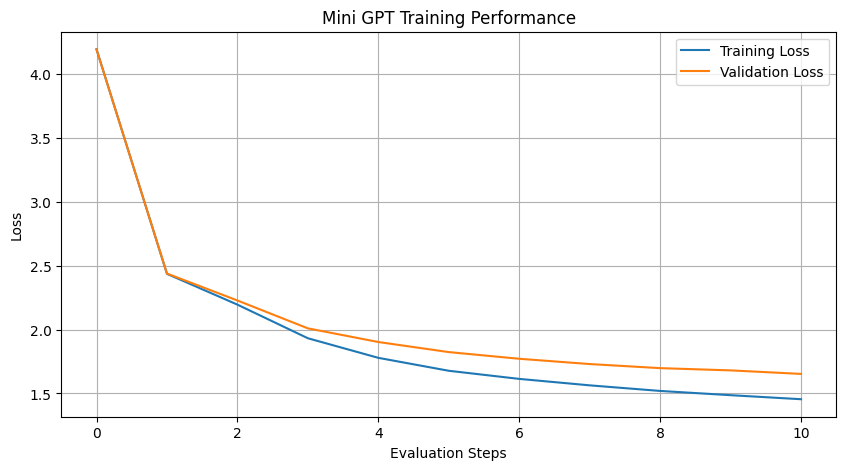

In [18]:

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Evaluation Steps")
plt.ylabel("Loss")

plt.title("Mini GPT Training Performance")

plt.legend()
plt.grid(True)

plt.show()


In [19]:

model.eval()

# Start with a prompt
prompt = "ROMEO:"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

# Generate text
with torch.no_grad():

    generated_ids = model.generate(
        context,
        max_new_tokens=500,
        temperature=0.8,
        top_k=40
    )

# Decode generated token IDs
generated_text = decode(
    generated_ids[0].tolist()
)

print("Generated text:\n")
print(generated_text)


Generated text:

ROMEO:
But you to desire say ball, which your gods.
And words, blission on warld their soldier brought:
What is throws your some that man in the ill unce.

HENRY BOLINGBROKE:
Do mine of the flown breather of Rome:
The gentleman, the first other see broking the weep;
A will good as both naturable of unto so peace.

CORIOLANUS:
And for the soldier tream;
Wherere-presed him have words conbraved of Dorford,
By made say her doth it my part of light and father?

LEONTES:
To warrit the abour
Marry son and so
